<a href="https://colab.research.google.com/github/awinarko-hue/Latihan/blob/main/IT_Platform/Tugas2_MapReduce_vs_Spark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 2 — Pipeline Pemrosesan Batch: MapReduce-style vs Spark DataFrame
**AGUS WINARKO:** 25.55.2877 · **Program:** S2 PJJ Informatika Universitas AMIKOM Yogyakarta

Notebook ini mengimplementasikan **dua versi pipeline batch pada dataset log server yang sama**, lalu membandingkan **waktu eksekusi** dan **resource usage** (CPU & memori):

| Versi | Implementasi | Keterangan |
|---|---|---|
| **A** | *MapReduce-style* dengan **PySpark RDD** | `flatMap` (fase **map**) → `reduceByKey` (fase **shuffle + reduce**) |
| **B** | **Spark DataFrame** | `regexp_extract` + `groupBy().agg()` (dioptimasi Catalyst) |

> **Catatan metodologi :** Versi A adalah *simulasi paradigma MapReduce di atas mesin Spark* (single-node Colab), **bukan Hadoop asli** (tanpa HDFS, tanpa penulisan shuffle ke disk antar-job seperti Hadoop). Karena itu perbedaan hasil mencerminkan perbedaan **model pemrograman (RDD berbasis Python vs DataFrame berbasis JVM/Catalyst)**, bukan perbandingan Hadoop vs Spark secara utuh.

**Alur notebook:** 1) Setup & Drive → 2) Sesi Spark → 3) Dataset & parser → 4) Pipeline A & B → 5) Verifikasi kebenaran → 6) Benchmark → 7) Visualisasi → 8) Kerangka analisis laporan.

## 1. Setup & koneksi Google Drive

In [ ]:
!pip -q install pyspark psutil

In [ ]:
import os, sys, glob

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# ====== KONFIGURASI (sesuaikan dengan struktur folder Drive ) ======
DRIVE_DIR    = '/content/drive/MyDrive/Kuliah/Tugas2/'     # folder kerja di Google Drive
DATASET_NAME = 'logfiles1.csv'                      # dataset log asli (sampel) di Drive
OUTPUT_DIR   = os.path.join(DRIVE_DIR, 'Tugas2_output')   # hasil benchmark (CSV/PNG) disimpan di sini
DATA_DIR     = '/content/data' if IN_COLAB else './data'  # data sintetis besar (disk lokal Colab, lebih cepat)
# ========================================================================

def find_dataset(name, base='/content/drive/MyDrive'):
    # cari file di seluruh Drive bila path default tidak cocok
    cand = os.path.join(DRIVE_DIR, name)
    if os.path.exists(cand):
        return cand
    hits = glob.glob(os.path.join(base, '**', name), recursive=True)
    return hits[0] if hits else None

DATASET_PATH = find_dataset(DATASET_NAME) if IN_COLAB else (DATASET_NAME if os.path.exists(DATASET_NAME) else None)
if not IN_COLAB or not os.path.isdir(os.path.dirname(OUTPUT_DIR) or '.'):
    OUTPUT_DIR = './output'
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

print('Dataset asli :', DATASET_PATH or 'TIDAK DITEMUKAN (notebook tetap jalan memakai data sintetis)')
print('Output       :', OUTPUT_DIR)
print('Data sintetis:', DATA_DIR)

Mounted at /content/drive
Dataset asli : /content/drive/MyDrive/Kuliah/Tugas2/logfiles1.csv
Output       : /content/drive/MyDrive/Kuliah/Tugas2/Tugas2_output
Data sintetis: /content/data


## 2. Membuat SparkSession (mode lokal)

In [ ]:
import time, gc, re, random, threading
import psutil
import pandas as pd
import matplotlib.pyplot as plt
from operator import add
from pyspark.sql import SparkSession, functions as F

N_CORES = os.cpu_count() or 2
spark = (SparkSession.builder
         .appName('Tugas2-MapReduce-vs-Spark')
         .master(f'local[{N_CORES}]')
         .config('spark.driver.memory', '4g')
         .config('spark.sql.shuffle.partitions', str(N_CORES * 2))   # default 200 terlalu besar untuk single-node
         .config('spark.ui.showConsoleProgress', 'false')
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel('ERROR')
print('Spark', spark.version, '| cores:', N_CORES, '| RAM total (GB):', round(psutil.virtual_memory().total/1e9, 1))

Spark 4.0.4 | cores: 2 | RAM total (GB): 13.6


## 3. Dataset log & parser
Format baris (Apache access log, terbungkus tanda kutip ala CSV):
```
"233.223.117.90 - - [27/Dec/2037:12:00:00 +0530] ""DELETE /usr/admin HTTP/1.0"" 502 4963 ""-"" ""Mozilla/5.0 (...""  45"
```
Kolom user-agent mengandung koma sehingga `spark.read.csv` akan salah memecah kolom. Karena itu file dibaca **sebagai teks per baris** dan diparsing dengan **regex** (satu pola yang sama untuk kedua pipeline). Pola menerima tanda kutip ganda `""` (versi CSV) maupun `"` (log asli).

Field yang diekstrak: `ip`, `method`, `path`, `status`, `bytes`.

In [ ]:
# Satu pola regex dipakai oleh Python (RDD) dan Spark SQL (DataFrame) -> hasil parsing konsisten
LOG_PATTERN = r'^"?(\d{1,3}(?:\.\d{1,3}){3}) \S+ \S+ \[([^\]]+)\] "{1,2}([A-Z]+) (\S+) [^"]*"{1,2} (\d{3}) (\d+)'
LOG_RE = re.compile(LOG_PATTERN)

# Generator log sintetis (format sama dengan dataset asli) agar ukuran data bisa diskalakan
METHODS = ['GET', 'POST', 'PUT', 'DELETE']
PATHS   = ['/usr', '/usr/admin', '/usr/admin/developer', '/usr/login', '/usr/register', '/usr/profile',
           '/usr/settings', '/api/v1/items', '/api/v1/orders', '/static/app.js', '/static/style.css', '/index.html']
STATUS  = [200, 304, 403, 404, 500, 502]
UAS = ['Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/89.0.4380.0 Safari/537.36',
       'Mozilla/5.0 (Android 10; Mobile; rv:84.0) Gecko/84.0 Firefox/84.0',
       'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/14.0 Safari/605.1.15']

def generate_logs(path, n_lines, n_unique_ips=20_000, seed=42, chunk=100_000):
    rnd = random.Random(seed)
    ips = [f'{rnd.randint(1,254)}.{rnd.randint(0,255)}.{rnd.randint(0,255)}.{rnd.randint(1,254)}' for _ in range(n_unique_ips)]
    with open(path, 'w') as f:
        done = 0
        while done < n_lines:
            k = min(chunk, n_lines - done)
            ip  = rnd.choices(ips, k=k)
            mth = rnd.choices(METHODS, weights=[60, 25, 10, 5], k=k)
            pth = rnd.choices(PATHS, k=k)
            st  = rnd.choices(STATUS, weights=[55, 15, 8, 12, 5, 5], k=k)
            byt = [rnd.randint(500, 9000) for _ in range(k)]
            ua  = rnd.choices(UAS, k=k)
            rt  = [rnd.randint(1, 5000) for _ in range(k)]
            f.write('\n'.join(
                f'{a} - - [27/Dec/2037:12:00:00 +0530] "{m} {p} HTTP/1.0" {s} {b} "-" "{u}" {r}'
                for a, m, p, s, b, u, r in zip(ip, mth, pth, st, byt, ua, rt)) + '\n')
            done += k
    return path

def ensure_dataset(n_lines):
    path = os.path.join(DATA_DIR, f'logs_{n_lines}.log')
    if not os.path.exists(path):
        t0 = time.perf_counter()
        generate_logs(path, n_lines)
        print(f'  dataset {n_lines:>9,} baris dibuat ({os.path.getsize(path)/1e6:.1f} MB, {time.perf_counter()-t0:.1f}s)')
    return path

## 4. Dua versi pipeline (analisis identik)
Kedua pipeline menghitung hal yang sama dari log:
1. jumlah request per **status HTTP**
2. jumlah request dan total **bytes** per **path/endpoint**
3. **10 IP** teratas berdasarkan jumlah request

Seluruh waktu (baca file → parsing → agregasi → `collect`) dihitung dalam pengukuran.

In [ ]:
# ---------- Pipeline A: MapReduce-style (RDD) ----------
def pipeline_rdd(path):
    lines = sc.textFile(path)

    # FASE MAP: tiap baris log -> beberapa pasangan (key, value) bertag
    def mapper(line):
        m = LOG_RE.match(line)
        if m is None:
            return []
        ip, _ts, _method, url, status, nbytes = m.groups()
        return [(('status', int(status)), (1, 0)),
                (('path', url),           (1, int(nbytes))),
                (('ip', ip),              (1, 0))]

    # FASE SHUFFLE + REDUCE: gabungkan value per key (combiner otomatis lewat reduceByKey)
    reduced = lines.flatMap(mapper).reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    out = reduced.collect()

    status_counts = {k[1]: v[0] for k, v in out if k[0] == 'status'}
    path_stats    = {k[1]: (v[0], v[1]) for k, v in out if k[0] == 'path'}
    ip_counts     = sorted(((k[1], v[0]) for k, v in out if k[0] == 'ip'), key=lambda x: (-x[1], x[0]))[:10]
    return {'status': status_counts, 'path': path_stats, 'top_ip': ip_counts}


# ---------- Pipeline B: Spark DataFrame ----------
def pipeline_df(path):
    raw = spark.read.text(path)
    parsed = (raw.select(F.regexp_extract('value', LOG_PATTERN, 1).alias('ip'),
                         F.regexp_extract('value', LOG_PATTERN, 4).alias('path'),
                         F.regexp_extract('value', LOG_PATTERN, 5).alias('status'),
                         F.regexp_extract('value', LOG_PATTERN, 6).alias('bytes'))
                  .filter(F.col('ip') != '')
                  .withColumn('status', F.col('status').cast('int'))
                  .withColumn('bytes', F.col('bytes').cast('long')))
    parsed.cache(); parsed.count()          # parsing sekali, dipakai tiga agregasi

    status_rows = parsed.groupBy('status').count().collect()
    path_rows   = parsed.groupBy('path').agg(F.count('*').alias('n'), F.sum('bytes').alias('b')).collect()
    ip_rows     = (parsed.groupBy('ip').count()
                         .orderBy(F.desc('count'), F.asc('ip')).limit(10).collect())
    parsed.unpersist()

    return {'status': {r['status']: r['count'] for r in status_rows},
            'path':   {r['path']: (r['n'], r['b']) for r in path_rows},
            'top_ip': [(r['ip'], r['count']) for r in ip_rows]}

PIPELINES = {'A: MapReduce-style (RDD)': pipeline_rdd, 'B: DataFrame': pipeline_df}

## 5. Verifikasi kebenaran implementasi
Hasil kedua pipeline harus **identik**. Diuji pada dataset asli dari Drive (bila ada) dan pada data sintetis kecil.

In [ ]:
def same_result(r1, r2):
    return r1['status'] == r2['status'] and r1['path'] == r2['path'] and r1['top_ip'] == r2['top_ip']

tests = []
if DATASET_PATH:
    tests.append(('dataset asli (Drive)', DATASET_PATH))
tests.append(('sintetis 10.000 baris', ensure_dataset(10_000)))

for label, p in tests:
    ra, rb = pipeline_rdd(p), pipeline_df(p)
    n = sum(ra['status'].values())
    total_lines = sum(1 for _ in open(p, errors='ignore'))
    print(f'[{label}] baris terparsing: {n}/{total_lines} | hasil A == B ? ->', same_result(ra, rb))
    print('   status:', dict(sorted(ra['status'].items())))
    assert same_result(ra, rb), 'Hasil kedua pipeline berbeda!'

  dataset    10,000 baris dibuat (2.0 MB, 0.1s)
[dataset asli (Drive)] baris terparsing: 549295/549295 | hasil A == B ? -> True
   status: {200: 78503, 303: 78139, 304: 78643, 403: 78618, 404: 77966, 500: 78345, 502: 79081}
[sintetis 10.000 baris] baris terparsing: 10000/10000 | hasil A == B ? -> True
   status: {200: 5480, 304: 1529, 403: 809, 404: 1220, 500: 459, 502: 503}


## 6. Benchmark (waktu eksekusi & resource usage)
Metrik per percobaan:
- **Waktu** — `time.perf_counter()` untuk satu pipeline penuh
- **CPU seconds** — total waktu CPU proses Python + JVM Spark + Python worker (dari `psutil`)
- **Rata-rata CPU %** — CPU seconds ÷ waktu (bisa > 100% karena multi-core)
- **Peak memori (RSS)** — puncak total memori semua proses tadi, disampel tiap 0,1 detik

Setiap kombinasi (ukuran data × pipeline) dijalankan beberapa kali setelah *warm-up*; dilaporkan rata-rata dan standar deviasi.

In [ ]:
class ResourceMonitor:
    # Sampling CPU time & memori proses ini + seluruh anak prosesnya (JVM Spark, Python worker)
    def __init__(self, interval=0.1):
        self.interval, self.peak_rss = interval, 0
        self.first, self.last = {}, {}
        self._stop = threading.Event()

    def _sample(self):
        me = psutil.Process()
        rss = 0
        for p in [me] + me.children(recursive=True):
            try:
                t = p.cpu_times(); cpu = t.user + t.system
                self.first.setdefault(p.pid, cpu)
                self.last[p.pid] = cpu
                rss += p.memory_info().rss
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                pass
        self.peak_rss = max(self.peak_rss, rss)

    def _loop(self):
        while not self._stop.is_set():
            self._sample(); time.sleep(self.interval)

    def __enter__(self):
        self._sample(); self._t = threading.Thread(target=self._loop, daemon=True); self._t.start(); return self
    def __exit__(self, *a):
        self._stop.set(); self._t.join(); self._sample()

    @property
    def cpu_seconds(self):
        return sum(self.last[p] - self.first[p] for p in self.last)

In [ ]:
# ====== PARAMETER BENCHMARK ======
SIZES = [10_000, 100_000, 1_000_000, 2_000_000]   # jumlah baris log (kurangi bila Colab terasa lambat)
RUNS  = 3                                          # pengulangan per kombinasi
# =================================

# Warm-up (tidak dicatat): menghangatkan JVM, kelas Spark, dan worker Python
w = ensure_dataset(SIZES[0])
for fn in PIPELINES.values():
    fn(w)

rows, check = [], {}
for n in SIZES:
    path = ensure_dataset(n)
    mb = os.path.getsize(path) / 1e6
    for name, fn in PIPELINES.items():
        for run in range(1, RUNS + 1):
            spark.catalog.clearCache(); gc.collect()
            with ResourceMonitor() as mon:
                t0 = time.perf_counter()
                res = fn(path)
                dt = time.perf_counter() - t0
            check.setdefault(n, {})[name] = res
            rows.append({'lines': n, 'size_mb': round(mb, 1), 'pipeline': name, 'run': run,
                         'time_s': dt, 'cpu_s': mon.cpu_seconds,
                         'avg_cpu_pct': 100 * mon.cpu_seconds / dt,
                         'peak_mem_mb': mon.peak_rss / 1e6})
            print(f'{n:>9,} baris | {name:<26} | run {run} | {dt:7.2f}s | CPU {mon.cpu_seconds:6.1f}s | peak {mon.peak_rss/1e6:7.0f} MB')

# kebenaran di semua ukuran data
for n, d in check.items():
    a, b = d.values()
    assert same_result(a, b), f'Hasil berbeda pada {n} baris'
print('\nVerifikasi: hasil pipeline A == B di semua ukuran data.')

raw_df = pd.DataFrame(rows)
raw_df.to_csv(os.path.join(OUTPUT_DIR, 'benchmark_raw.csv'), index=False)

   10,000 baris | A: MapReduce-style (RDD)   | run 1 |    0.35s | CPU    0.6s | peak    1506 MB
   10,000 baris | A: MapReduce-style (RDD)   | run 2 |    0.32s | CPU    0.6s | peak    1505 MB
   10,000 baris | A: MapReduce-style (RDD)   | run 3 |    0.34s | CPU    0.6s | peak    1518 MB
   10,000 baris | B: DataFrame               | run 1 |    0.90s | CPU    1.7s | peak    1519 MB
   10,000 baris | B: DataFrame               | run 2 |    2.58s | CPU    2.1s | peak    1535 MB
   10,000 baris | B: DataFrame               | run 3 |    1.22s | CPU    1.6s | peak    1548 MB
  dataset   100,000 baris dibuat (19.5 MB, 0.3s)
  100,000 baris | A: MapReduce-style (RDD)   | run 1 |    0.95s | CPU    1.8s | peak    1571 MB
  100,000 baris | A: MapReduce-style (RDD)   | run 2 |    0.86s | CPU    1.8s | peak    1581 MB
  100,000 baris | A: MapReduce-style (RDD)   | run 3 |    0.84s | CPU    1.5s | peak    1585 MB
  100,000 baris | B: DataFrame               | run 1 |    1.66s | CPU    3.1s | peak   

## 7. Hasil & visualisasi

In [ ]:
summary = (raw_df.groupby(['lines', 'size_mb', 'pipeline'])
                 .agg(time_mean=('time_s', 'mean'), time_std=('time_s', 'std'),
                      cpu_s=('cpu_s', 'mean'), avg_cpu_pct=('avg_cpu_pct', 'mean'),
                      peak_mem_mb=('peak_mem_mb', 'mean'))
                 .reset_index())
summary.to_csv(os.path.join(OUTPUT_DIR, 'benchmark_summary.csv'), index=False)
display(summary.round(2))

piv = summary.pivot(index='lines', columns='pipeline', values='time_mean')
a, b = piv.columns[0], piv.columns[1]
piv['speedup (A/B)'] = piv[a] / piv[b]
display(piv.round(2))

,lines,size_mb,pipeline,time_mean,time_std,cpu_s,avg_cpu_pct,peak_mem_mb
0,10000,2.0,A: MapReduce-style (RDD),0.34,0.01,0.63,187.33,1509.32
1,10000,2.0,B: DataFrame,1.57,0.89,1.82,134.39,1534.18
2,100000,19.5,A: MapReduce-style (RDD),0.88,0.06,1.69,190.85,1579.05
3,100000,19.5,B: DataFrame,1.75,0.16,3.22,184.68,1659.42
4,1000000,195.4,A: MapReduce-style (RDD),5.42,0.26,9.67,178.69,1771.73
5,1000000,195.4,B: DataFrame,10.81,1.45,18.35,170.71,1741.28
6,2000000,390.6,A: MapReduce-style (RDD),11.14,1.32,19.58,176.74,1959.96
7,2000000,390.6,B: DataFrame,20.52,0.55,31.46,153.36,1792.28


pipeline,A: MapReduce-style (RDD),B: DataFrame,speedup (A/B)
lines,,,
10000,0.34,1.57,0.22
100000,0.88,1.75,0.51
1000000,5.42,10.81,0.50
2000000,11.14,20.52,0.54


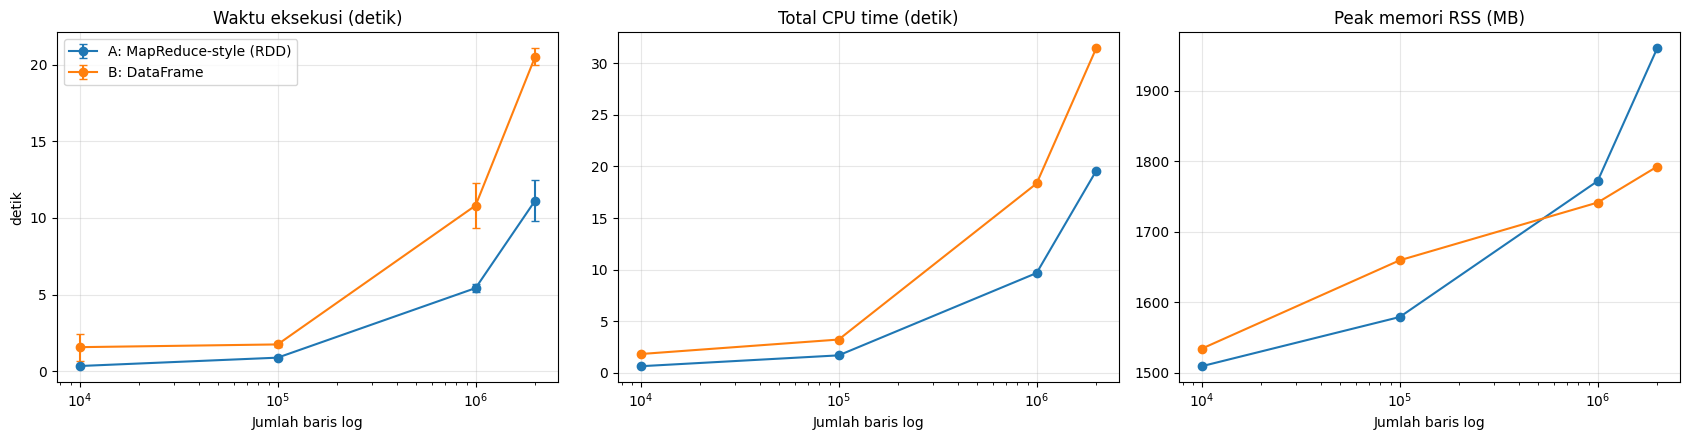

Tersimpan di: /content/drive/MyDrive/Kuliah/Tugas2/Tugas2_output


In [ ]:
metrics = [('time_mean', 'Waktu eksekusi (detik)', 'time_std'),
           ('cpu_s', 'Total CPU time (detik)', None),
           ('peak_mem_mb', 'Peak memori RSS (MB)', None)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (col, title, err) in zip(axes, metrics):
    for name, g in summary.groupby('pipeline'):
        ax.errorbar(g['lines'], g[col], yerr=g[err] if err else None, marker='o', capsize=3, label=name)
    ax.set_xscale('log'); ax.set_xlabel('Jumlah baris log'); ax.set_title(title); ax.grid(alpha=.3)
axes[0].set_ylabel('detik'); axes[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'benchmark_chart.png'), dpi=150)
plt.show()
print('Tersimpan di:', OUTPUT_DIR)

## 8. Ringkasan otomatis untuk laporan

In [ ]:
big = summary[summary['lines'] == summary['lines'].max()].set_index('pipeline')
a, b = big.index[0], big.index[1]
print(f"Pada {int(big['lines'].iloc[0]):,} baris ({big['size_mb'].iloc[0]} MB):")
print(f"- Waktu   : {a} = {big.loc[a,'time_mean']:.2f}s vs {b} = {big.loc[b,'time_mean']:.2f}s "
      f"-> {big.loc[a,'time_mean']/big.loc[b,'time_mean']:.2f}x")
print(f"- CPU time: {big.loc[a,'cpu_s']:.1f}s vs {big.loc[b,'cpu_s']:.1f}s")
print(f"- Peak mem: {big.loc[a,'peak_mem_mb']:.0f} MB vs {big.loc[b,'peak_mem_mb']:.0f} MB")

Pada 2,000,000 baris (390.6 MB):
- Waktu   : A: MapReduce-style (RDD) = 11.14s vs B: DataFrame = 20.52s -> 0.54x
- CPU time: 19.6s vs 31.5s
- Peak mem: 1960 MB vs 1792 MB


### Kerangka analisis komparatif (lengkapi setelah melihat hasil)
1. **Kebenaran:** kedua pipeline menghasilkan output identik (lihat bagian 5 dan 6).
2. **Waktu eksekusi:** pipeline mana lebih cepat dan pada ukuran data berapa selisih mulai terlihat? Pada data kecil, overhead *startup/scheduling* biasanya mendominasi.
3. **Resource usage:** bandingkan CPU time dan peak memori. RDD menjalankan parsing di **Python worker** (serialisasi JVM↔Python), sedangkan DataFrame memakai `regexp_extract` di **JVM** (kode tergenerasi Catalyst/Tungsten).
4. **Penyebab perbedaan:** jelaskan berdasarkan hasil Anda sendiri. Faktor yang layak dibahas: overhead perencanaan query & beberapa job Spark pada DataFrame (parsing + cache + tiga agregasi), single-pass `reduceByKey` dengan combiner pada RDD, serialisasi JVM↔Python, optimasi Catalyst/Tungsten yang makin terasa pada data besar dan jumlah core lebih banyak.
5. **Keterbatasan:** (a) simulasi MapReduce di atas Spark, bukan Hadoop asli; (b) Colab single-node dengan sedikit core; (c) data sintetis (distribusi key sederhana); (d) variasi performa antar-sesi Colab.
6. **Kesimpulan & saran:** kapan paradigma MapReduce klasik masih relevan, dan kapan DataFrame lebih tepat.